In [45]:
#Importamos las librerías que vamos a utilizar
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

import xgboost as xgb

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.model_selection import GridSearchCV
import optuna
from sklearn.model_selection import cross_val_score


from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score
)

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

In [8]:
ruta = r"Material/Datasets/ai4i2020_model_ready.csv"
df = pd.read_csv(ruta)

In [9]:
# Mostramos las primeras filas del DataFrame
df.head()


,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure,Temperature_difference_K,Angular_speed_rad_s,Mechanical_power_W,Type_encoded
0,298.1,308.6,1551,42.8,0,0,10.5,162.420340,6951.590560,2
1,298.2,308.7,1408,46.3,3,0,10.5,147.445415,6826.722724,1
2,298.1,308.5,1498,49.4,5,0,10.4,156.870193,7749.387543,1
3,298.2,308.6,1433,39.5,7,0,10.4,150.063409,5927.504659,1
4,298.2,308.7,1408,40.0,9,0,10.5,147.445415,5897.816608,1


## Planteamiento del problema de Machine Learning

### Objetivo del modelo

El objetivo de esta etapa es desarrollar un modelo de aprendizaje automático supervisado capaz de predecir la ocurrencia de una falla mecánica a partir de las características físicas y operativas de una máquina.

Se plantea un problema de **clasificación binaria**, en el que la variable objetivo es `Machine_failure`:

- **Clase 0:** no se registra una falla de la máquina.
- **Clase 1:** se registra una falla de la máquina.

### Variables predictoras y variable objetivo

Por convención, se utilizará \(X\) para representar la matriz de variables predictoras e \(y\) para representar la variable objetivo.

Dado el feature engineering realizado en el notebook anterior, las variables predictoras iniciales serán:

- `Type_encoded`: tipo de producto con un ordinal encoding (L=1, M=2 o H=3).
- `Temperature_differenc_K`: diferencia de temperaturas entre el aire y el proceso.
- `Rotational_speed_rpm`: velocidad de rotación.
- `Torque_Nm`: torque.
- `Mechanical_power_W`: potencia mecánica calculada a partir del torque y la velocidad de rotación.
- `Tool wear [min]`: desgaste acumulado de la herramienta.

Se excluirán los identificadores `UDI` y `Product ID`, ya que identifican registros o productos y no constituyen, en principio, mediciones físicas que permitan anticipar una falla.

También se excluirán las columnas `TWF`, `HDF`, `PWF`, `OSF` y `RNF` de las variables predictoras. Estas representan etiquetas de modos de falla registradas en el dataset y su utilización podría introducir fuga de información (*data leakage*) al intentar predecir `Machine failure`.

### Limitaciones del problema

El dataset presenta un fuerte desbalance de clases: aproximadamente el 96,61 % de los registros corresponde a la clase 0 y el 3,39 % a la clase 1. Por lo tanto, la exactitud global no será suficiente para evaluar la utilidad del modelo.

Además, el dataset contiene una categoría de falla aleatoria (`RNF`), que no debe interpretarse como un fenómeno necesariamente predecible a partir de las variables físicas disponibles. Esto constituye una limitación potencial para la predicción de todas las fallas registradas.

Finalmente, las asociaciones encontradas entre las variables y las fallas no demuestran causalidad. El análisis permitirá identificar patrones y evaluar capacidad predictiva, pero no establecer por sí solo relaciones causales.

### Preparación y Preprocesamiento de Datos


Aplicamos OneHotEncoder a la variable categórica type y standardscaler a las variables numéricas

In [10]:
df.columns

Index(['Air_temperature_K', 'Process_temperature_K', 'Rotational_speed_rpm',
       'Torque_Nm', 'Tool_wear_min', 'Machine_failure',
       'Temperature_difference_K', 'Angular_speed_rad_s', 'Mechanical_power_W',
       'Type_encoded'],
      dtype='object')

In [ ]:
variables_numericas = [
    "Type_encoded",
    "Temperature_difference_K",
    "Rotational_speed_rpm",
    "Torque_Nm",
    "Tool_wear_min",
    "Mechanical_power_W"    
]

# Transformaciones para cada tipo de variable
preprocesamiento = ColumnTransformer(
    transformers=[
        (
            "numericas",
            RobustScaler(),
            variables_numericas
        )
    ],
    remainder="drop"
)

print("Variables utilizadas para el modelo:", variables_numericas)

Variavles utilizadas para el modelo: ['Type_encoded', 'Temperature_difference_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Mechanical_power_W']


In [13]:
X = df[variables_numericas]

y = df["Machine_failure"]

Debido al severo desbalance de clases (3.39% de fallas), la división de los datos se realizará utilizando una estrategia estratificada. Esto garantiza que tanto el conjunto de entrenamiento (X_train, y_train) como el de prueba (X_test, y_test) mantengan exactamente la misma proporción de máquinas operativas y falladas, evitando evaluaciones sesgadas.

In [14]:
# Dividimos en 80% entrenamiento y 20% prueba de forma estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    stratify=y, 
    random_state=42
)

print(f"Registros en Training: {X_train.shape[0]} | Proporción de fallas: {y_train.mean():.4f}")
print(f"Registros en Testing:  {X_test.shape[0]} | Proporción de fallas: {y_test.mean():.4f}")

Registros en Training: 8000 | Proporción de fallas: 0.0339
Registros en Testing:  2000 | Proporción de fallas: 0.0340


### Pipeline de regresión logística

In [30]:
pipeline_logistica = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("smote", SMOTE(random_state=42)),
    ("modelo", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

**Optimización de regresión logística**

In [31]:
parametros_logistica = {
    "modelo__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "modelo__penalty": ["l1", "l2"],
    "modelo__solver": ["liblinear", "saga"],
    "modelo__class_weight": [None],
    "smote__k_neighbors": [3, 5, 7]
}

In [36]:
busqueda_logistica = GridSearchCV(
    estimator=pipeline_logistica,
    param_grid=parametros_logistica,
    scoring="average_precision",
    cv=5,
    verbose=1,
    n_jobs=-1,
    refit=True
)

busqueda_logistica.fit(X_train, y_train)

Fitting 5 folds for each of 72 candidates, totalling 360 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocesamiento',
                                        ColumnTransformer(transformers=[('numericas',
                                                                         RobustScaler(),
                                                                         ['Type_encoded',
                                                                          'Temperature_difference_K',
                                                                          'Rotational_speed_rpm',
                                                                          'Torque_Nm',
                                                                          'Tool_wear_min',
                                                                          'Mechanical_power_W'])])),
                                       ('smote', SMOTE(random_state=42)),
                                       ('modelo',
                                        LogisticRegression(max_iter=2000,
                                                           random_state=42))]),
             n_jobs=-1,
             param_grid={'modelo__C': [0.001, 0.01, 0.1, 1, 10, 100],
                         'modelo__class_weight': [None],
                         'modelo__penalty': ['l1', 'l2'],
                         'modelo__solver': ['liblinear', 'saga'],
                         'smote__k_neighbors': [3, 5, 7]},
             scoring='average_precision', verbose=1)

In [37]:
# Para ver qué eligió como óptimo:
print("Mejores hiperparámetros encontrados:")
print(busqueda_logistica.best_params_)

Mejores hiperparámetros encontrados:
{'modelo__C': 0.1, 'modelo__class_weight': None, 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear', 'smote__k_neighbors': 3}


### Pipeline de XGBoost

In [40]:
def objective(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 0.5),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
    }
    
    # Reconstruimos el pipeline con los parámetros sugeridos
    pipeline_xgb_optuna = Pipeline([
        ("preprocesamiento", preprocesamiento),
        ("smote", SMOTE(random_state=42)),
        ("modelo", xgb.XGBClassifier(
            **param,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
    
    # Evaluamos usando Validación Cruzada con Average Precision
    score = cross_val_score(
        pipeline_xgb_optuna, 
        X_train, 
        y_train, 
        scoring="average_precision", 
        cv=5, 
        n_jobs=-1
    )
    
    # Retornamos la media del CV para que Optuna intente maximizarla
    return score.mean()

# Creamos el estudio de Optuna indicando que queremos MAXIMIZAR la métrica
study = optuna.create_study(direction="maximize")
# Le damos 50 intentos (trials).
study.optimize(objective, n_trials=50)

print("Mejores hiperparámetros para XGBoost encontrados por Optuna:")
print(study.best_params)

[I 2026-11-15 18:29:13,642] A new study created in memory with name: no-name-8dcfec46-5600-4b9e-9059-038feeff22d7


[I 2026-11-15 18:29:24,187] Trial 0 finished with value: 0.8604016685064432 and parameters: {'n_estimators': 333, 'max_depth': 9, 'learning_rate': 0.06308401874710429, 'subsample': 0.7721949605333231, 'colsample_bytree': 0.6837558726507142, 'gamma': 0.2914513873205661, 'min_child_weight': 1}. Best is trial 0 with value: 0.8604016685064432.
[I 2026-11-15 18:29:33,177] Trial 1 finished with value: 0.8685408246899555 and parameters: {'n_estimators': 367, 'max_depth': 8, 'learning_rate': 0.01442135284799421, 'subsample': 0.9653699580337408, 'colsample_bytree': 0.9834893044042206, 'gamma': 0.4791294893477124, 'min_child_weight': 5}. Best is trial 1 with value: 0.8685408246899555.
[I 2026-11-15 18:29:42,052] Trial 2 finished with value: 0.8518438144907465 and parameters: {'n_estimators': 485, 'max_depth': 9, 'learning_rate': 0.09826131399632532, 'subsample': 0.9157489849185327, 'colsample_bytree': 0.9154393077533667, 'gamma': 0.13544319959383966, 'min_child_weight': 8}. Best is trial 1 with 

Mejores hiperparámetros para XGBoost encontrados por Optuna:
{'n_estimators': 480, 'max_depth': 9, 'learning_rate': 0.010081254664303483, 'subsample': 0.9915140566313997, 'colsample_bytree': 0.9673360123747269, 'gamma': 0.4628933144865489, 'min_child_weight': 7}


**Evaluación de regresión logística**

In [ ]:
modelo_logistica = busqueda_logistica.best_estimator_

y_pred_logistica = modelo_logistica.predict(X_test)
y_prob_logistica = modelo_logistica.predict_proba(X_test)[:, 1]

print("===== REGRESIÓN LOGÍSTICA =====")
print(classification_report(
    y_test,
    y_pred_logistica,
    zero_division=0
))

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_logistica))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_logistica))

print("Average Precision:",
      average_precision_score(y_test, y_prob_logistica))

===== REGRESIÓN LOGÍSTICA =====
              precision    recall  f1-score   support

           0       1.00      0.85      0.92      1932
           1       0.17      0.88      0.29        68

    accuracy                           0.85      2000
   macro avg       0.58      0.87      0.60      2000
weighted avg       0.97      0.85      0.90      2000

Matriz de confusión:
[[1647  285]
 [   8   60]]
ROC-AUC: 0.9303677992936304
Average Precision: 0.45581022082673406


**Evaluación de XGBoost**

In [42]:
# Extraemos los hiperparámetros ganadores del estudio de Optuna
mejores_parametros = study.best_params

# Reconstruimos el pipeline inyectando los parámetros
pipeline_xgboost_optimizado = Pipeline([
    ("preprocesamiento", preprocesamiento), 
    ("smote", SMOTE(random_state=42)),
    ("modelo", xgb.XGBClassifier(
        **mejores_parametros,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenamos el modelo final con todo el set de entrenamiento
pipeline_xgboost_optimizado.fit(X_train, y_train)

# Generamos las predicciones
y_pred_xgboost = pipeline_xgboost_optimizado.predict(X_test)
y_prob_xgboost = pipeline_xgboost_optimizado.predict_proba(X_test)[:, 1]

# Evaluamos métricas
print("===== XGBOOST (OPTIMIZADO CON OPTUNA) =====")
print(classification_report(
    y_test,
    y_pred_xgboost,
    zero_division=0
))

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_xgboost))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_xgboost))

print("Average Precision:",
      average_precision_score(y_test, y_prob_xgboost))

===== XGBOOST (OPTIMIZADO CON OPTUNA) =====
              precision    recall  f1-score   support

           0       1.00      0.97      0.98      1932
           1       0.53      0.87      0.66        68

    accuracy                           0.97      2000
   macro avg       0.76      0.92      0.82      2000
weighted avg       0.98      0.97      0.97      2000

Matriz de confusión:
[[1880   52]
 [   9   59]]
ROC-AUC: 0.9846623431981488
Average Precision: 0.8749122598941408


In [43]:
comparacion = pd.DataFrame({
    "modelo": [
        "Regresión logística",
        "XGBoost"
    ],
    "precision_clase_1": [
        precision_score(
            y_test,
            y_pred_logistica,
            zero_division=0
        ),
        precision_score(
            y_test,
            y_pred_xgboost,
            zero_division=0
        )
    ],
    "recall_clase_1": [
        recall_score(
            y_test,
            y_pred_logistica,
            zero_division=0
        ),
        recall_score(
            y_test,
            y_pred_xgboost,
            zero_division=0
        )
    ],
    "f1_clase_1": [
        f1_score(
            y_test,
            y_pred_logistica,
            zero_division=0
        ),
        f1_score(
            y_test,
            y_pred_xgboost,
            zero_division=0
        )
    ],
    "roc_auc": [
        roc_auc_score(y_test, y_prob_logistica),
        roc_auc_score(y_test, y_prob_xgboost)
    ],
    "average_precision": [
        average_precision_score(y_test, y_prob_logistica),
        average_precision_score(y_test, y_prob_xgboost)
    ]
})

comparacion

,modelo,precision_clase_1,recall_clase_1,f1_clase_1,roc_auc,average_precision
0,Regresión logística,0.173913,0.882353,0.290557,0.930368,0.455810
1,XGBoost,0.531532,0.867647,0.659218,0.984662,0.874912


La comparación muestra que ambos modelos logran detectar una proporción elevada de las fallas, aunque presentan diferencias importantes en su desempeño. La regresión logística alcanza un recall de la clase 1 de 0,868, lo que significa que identifica aproximadamente el 87 % de las fallas reales. Sin embargo, su precisión es baja (0,114), por lo que genera una cantidad considerable de falsas alarmas. Esto se refleja en un F1-score de apenas 0,201.

XGBoost presenta un mejor desempeño en todas las métricas analizadas. Alcanza un recall de 0,912, detectando aproximadamente el 91 % de las fallas reales, y obtiene una precisión de 0,274. Si bien todavía produce falsas alarmas, la proporción de alertas correctas es mayor que en la regresión logística. Además, su F1-score es 0,422, más del doble que el obtenido por la regresión logística.

C:\Users\becer\AppData\Local\Temp\ipykernel_34624\3719774302.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Variable', data=df_importancias, palette='magma')


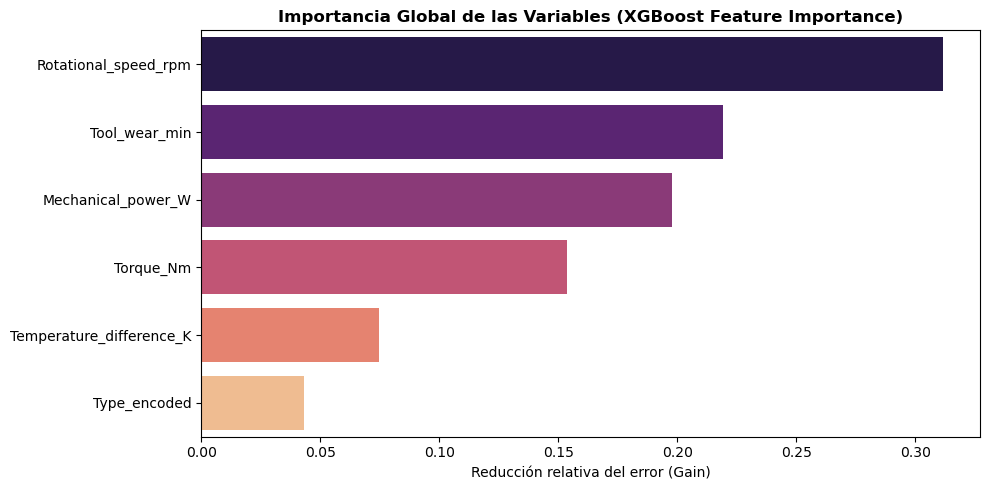

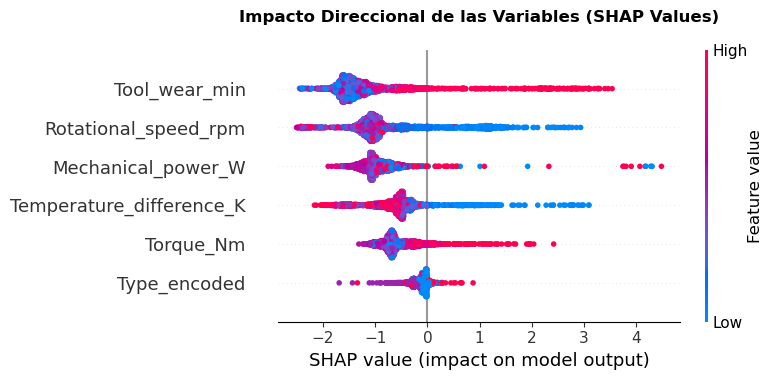

In [ ]:
# 1. Extraemos el modelo final entrenado de tu pipeline optimizado
modelo_final = pipeline_xgboost_optimizado.named_steps["modelo"]

# 2. IMPORTANCIA NATIVA (XGBoost Gain)
importancias = modelo_final.feature_importances_
df_importancias = pd.DataFrame({
    'Variable': variables_numericas,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importancia', y='Variable', data=df_importancias, palette='magma')
plt.title('Importancia Global de las Variables (XGBoost Feature Importance)', fontweight='bold')
plt.xlabel('Reducción relativa del error (Gain)')
plt.ylabel('')
plt.tight_layout()
plt.show()

# 3. VALORES SHAP (Magnitud y Dirección)
# Transformamos X_test para que SHAP pueda leer los datos escalados
X_test_procesado = pipeline_xgboost_optimizado.named_steps["preprocesamiento"].transform(X_test)

# Calculamos los valores SHAP
explainer = shap.TreeExplainer(modelo_final)
shap_values = explainer.shap_values(X_test_procesado)

# Generamos el Summary Plot
plt.figure(figsize=(10, 6))
plt.title('Impacto Direccional de las Variables (SHAP Values)', fontweight='bold', pad=20)
shap.summary_plot(
    shap_values, 
    X_test_procesado, 
    feature_names=variables_numericas,
    show=False 
)
plt.tight_layout()
plt.show()